# Mapping the Competitiveness Divide: Philippine Cities & Municipalities (CMCI 2024)

This notebook analyzes the **Cities and Municipalities Competitiveness Index (CMCI) 2024**, published by the Philippine Department of Trade and Industry (DTI). The CMCI scores all **1,634** local government units (LGUs) on five pillars: *Economic Dynamism, Government Efficiency, Infrastructure, Resiliency,* and *Innovation*. These pillars are built from **50 sub-indicators**.

**Questions**
1. Do LGUs fall into natural competitiveness tiers?
2. Which specific sub-indicators separate the tiers, and which LGUs are most at risk?

**Approach**

| Step | Technique | Output |
|---|---|---|
| 1. Explore | Descriptive statistics, distributions, correlations | Understanding of score patterns across LGU types |
| 2. Cluster | K-Means on standardized pillar scores (K chosen by elbow + silhouette), PCA for visualization | 3 competitiveness tiers |
| 3. Explain | L1-penalized multinomial logistic regression on the 50 raw sub-indicators | Sparse set of drivers for each tier, plus an at-risk watchlist |

Figures are saved to `figures/` and used in the accompanying paper (`report/report.pdf`).

## Setup

In [1]:
import os
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegressionCV

import warnings
warnings.filterwarnings('ignore')   # silence KMeans / saga convergence chatter

sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline

FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name, fig=None):
    # Save the current (or given) figure to figures/<name>.png at 150 dpi
    (fig or plt.gcf()).savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=150, bbox_inches='tight')

# ── Shared constants ─────────────────────────────────────────────────────────
PILLAR_COLS   = ['economic_dynamism', 'gov_efficiency', 'infrastructure',
                 'resiliency', 'innovation']
PILLAR_LABELS = ['Economic\nDynamism', 'Government\nEfficiency',
                 'Infrastructure', 'Resiliency', 'Innovation']

CLUSTER_NAMES  = {0: 'Competitive Leaders', 1: 'Critically Underserved', 2: 'Developing Mainstream'}
CLUSTER_SHORT  = {0: 'Leaders', 1: 'Underserved', 2: 'Mainstream'}
CLUSTER_COLORS = {0: '#2196F3', 1: '#F44336', 2: '#4CAF50'}

# Sub-indicator column prefixes → pillar
PILLAR_PREFIX_NAMES  = {'ed_': 'Economic Dynamism', 'ge_': 'Government Efficiency',
                        'infra_': 'Infrastructure', 'res_': 'Resiliency', 'inn_': 'Innovation'}
PILLAR_PREFIX_COLORS = {'ed_': '#2196F3', 'ge_': '#4CAF50', 'infra_': '#FF9800',
                        'res_': '#9C27B0', 'inn_': '#F44336'}
PILLAR_LEGEND = [Patch(facecolor=PILLAR_PREFIX_COLORS[p], label=n)
                 for p, n in [('inn_', 'Innovation'), ('ge_', 'Gov Efficiency'),
                              ('ed_', 'Economic Dynamism'), ('res_', 'Resiliency'),
                              ('infra_', 'Infrastructure')]]

def pillar_color(indicator):
    for prefix, color in PILLAR_PREFIX_COLORS.items():
        if indicator.startswith(prefix):
            return color
    return 'gray'

def clean_label(indicator):
    # 'inn_stem_graduates' → 'Stem Graduates'
    return indicator.split('_', 1)[1].replace('_', ' ').title()

## 1. Data

### 1.1 Collect rankings from the DTI website
The saved `data/cmci_2024_all.csv` is used by default. Set `REFRESH_DATA = True` to re-download the five ranking tables (one per LGU category) from [cmci.dti.gov.ph](https://cmci.dti.gov.ph).

In [2]:
REFRESH_DATA = False
RANKINGS_CSV = 'data/cmci_2024_all.csv'

if REFRESH_DATA:
    urls = [
        "https://cmci.dti.gov.ph/rankings-data.php?unit=Highly+Urbanized+Cities",
        "https://cmci.dti.gov.ph/rankings-data.php?unit=Component+Cities",
        "https://cmci.dti.gov.ph/rankings-data.php?unit=1st+to+2nd+Class+Municipalities",
        "https://cmci.dti.gov.ph/rankings-data.php?unit=3rd+to+4th+Class+Municipalities",
        "https://cmci.dti.gov.ph/rankings-data.php?unit=5th+to+6th+Class+Municipalities",
    ]
    cmci_all = pd.concat([pd.read_html(url)[0] for url in urls], ignore_index=True)
    cmci_all.to_csv(RANKINGS_CSV, index=False)
    print(f"Downloaded {len(cmci_all):,} rows → {RANKINGS_CSV}")

### 1.2 Load and clean
The five tables are stacked in category order, so the LGU type is assigned by row position. The check below confirms that each boundary row is the #1-ranked LGU of its category.

In [3]:
df = pd.read_csv(RANKINGS_CSV, skiprows=[1])

df = df.rename(columns={
    'Score': 'overall_score',
    'Economic Dynamism.1': 'economic_dynamism',
    'Government Efficiency.1': 'gov_efficiency',
    'Infrastructure.1': 'infrastructure',
    'Resiliency.1': 'resiliency',
    'Innovation.1': 'innovation',
    'Economic Dynamism': 'ed_rank',
    'Government Efficiency': 'ge_rank',
    'Infrastructure': 'infra_rank',
    'Resiliency': 'resiliency_rank',
    'Innovation': 'innovation_rank',
})

LGU_TYPES = ['Highly Urbanized Cities', 'Component Cities',
             '1st-2nd Class Municipalities', '3rd-4th Class Municipalities',
             '5th-6th Class Municipalities']
boundaries = [0, 33, 149, 658, 1318, len(df)]

df['lgu_type'] = ''
for i, lgu_type in enumerate(LGU_TYPES):
    df.loc[boundaries[i]:boundaries[i + 1] - 1, 'lgu_type'] = lgu_type

score_cols = ['overall_score'] + PILLAR_COLS
df[score_cols] = df[score_cols].apply(pd.to_numeric, errors='coerce')

print(f"{len(df):,} LGUs loaded\n")
print(df.iloc[boundaries[:-1]][['LGU', 'Province', 'lgu_type', 'overall_score']].to_string())

1,634 LGUs loaded

              LGU         Province                      lgu_type  overall_score
0     Quezon (MM)     Metro Manila       Highly Urbanized Cities        60.6893
33      Naga (CS)    Camarines Sur              Component Cities        58.2084
149        Cainta            Rizal  1st-2nd Class Municipalities        44.8114
658      Can-Avid    Eastern Samar  3rd-4th Class Municipalities        40.3895
1318    Kauswagan  Lanao Del Norte  5th-6th Class Municipalities        45.3314


## 2. Exploratory analysis

In [4]:
desc = df[PILLAR_COLS + ['overall_score']].agg(
    ['mean', 'median', 'std', 'min', 'max',
     lambda x: x.quantile(0.25),
     lambda x: x.quantile(0.75)]
)
desc.index = ['Mean', 'Median', 'Std Dev', 'Min', 'Max', 'Q1 (25%)', 'Q3 (75%)']
desc.loc['IQR'] = desc.loc['Q3 (75%)'] - desc.loc['Q1 (25%)']
desc.round(4)

,economic_dynamism,gov_efficiency,infrastructure,resiliency,innovation,overall_score
Mean,4.0437,7.8634,2.9076,10.9525,4.6516,30.4188
Median,4.0160,8.1130,2.6962,11.2907,4.4532,30.3645
Std Dev,1.0711,1.7793,1.0727,1.4900,2.2152,5.9398
Min,0.0016,0.0000,0.0000,0.0000,0.0000,0.2597
Max,9.7284,14.3658,13.2788,16.5126,12.2489,60.6893
Q1 (25%),3.3618,7.0908,2.3698,10.8314,3.0518,27.3762
Q3 (75%),4.5774,8.8006,3.2120,11.4521,6.4336,33.6128
IQR,1.2157,1.7098,0.8422,0.6207,3.3818,6.2367


### Pillar score distributions
- **Resiliency** is the most evenly distributed pillar. Most LGUs score around 10–12, reflecting national disaster-preparedness mandates.
- **Infrastructure** and **Innovation** are heavily right-skewed. Most LGUs score very low and a small elite scores high.
- **Government Efficiency** has the widest spread.
- These are uneven, multi-modal distributions, which motivates clustering.

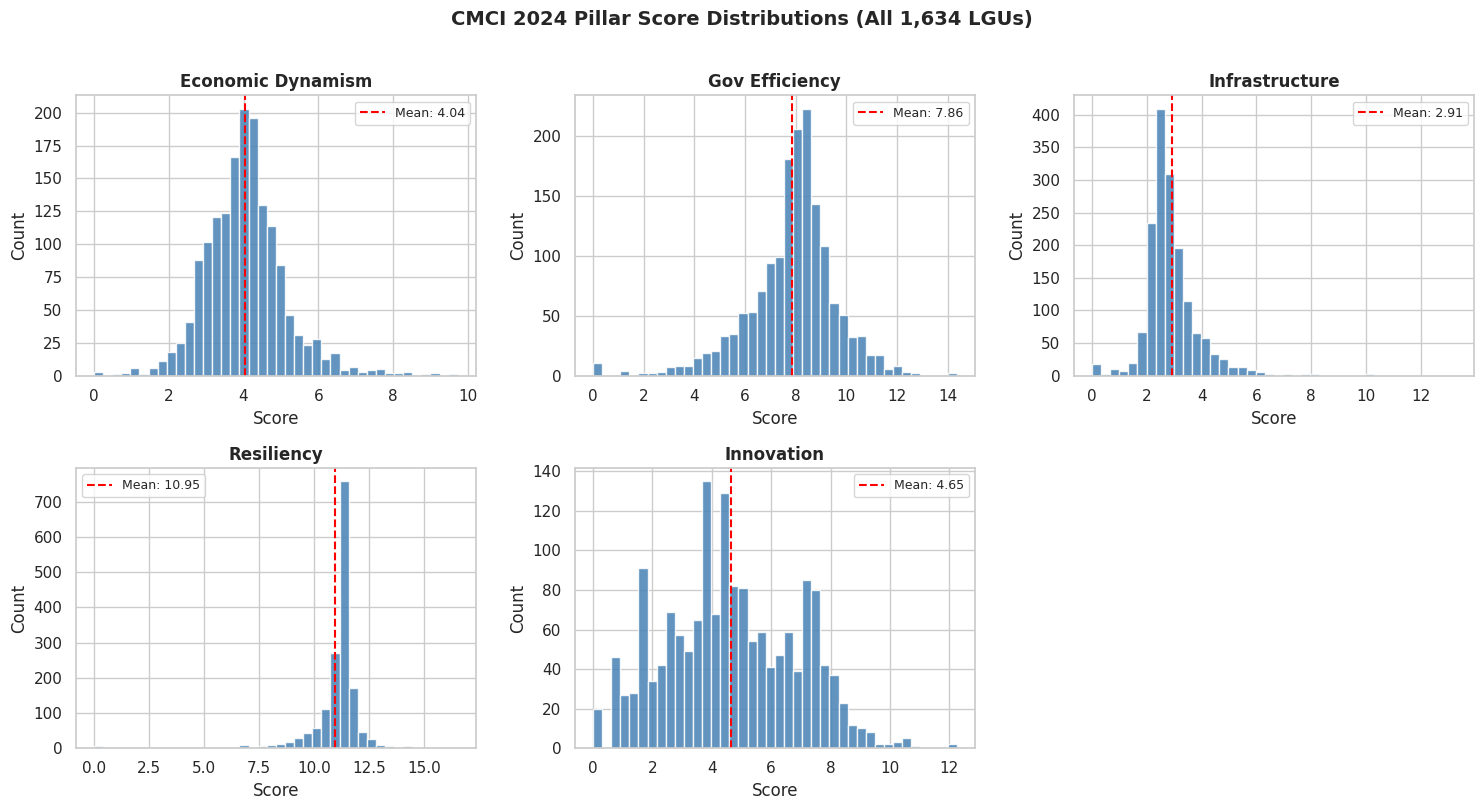

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(PILLAR_COLS):
    axes[i].hist(df[col].dropna(), bins=40, color='steelblue', edgecolor='white', alpha=0.85)
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Score')
    axes[i].set_ylabel('Count')
    mean_val = df[col].mean()
    axes[i].axvline(mean_val, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mean_val:.2f}')
    axes[i].legend(fontsize=9)
axes[5].set_visible(False)
plt.suptitle('CMCI 2024 Pillar Score Distributions (All 1,634 LGUs)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('chart_03')
plt.show()

### Pillar scores by LGU type

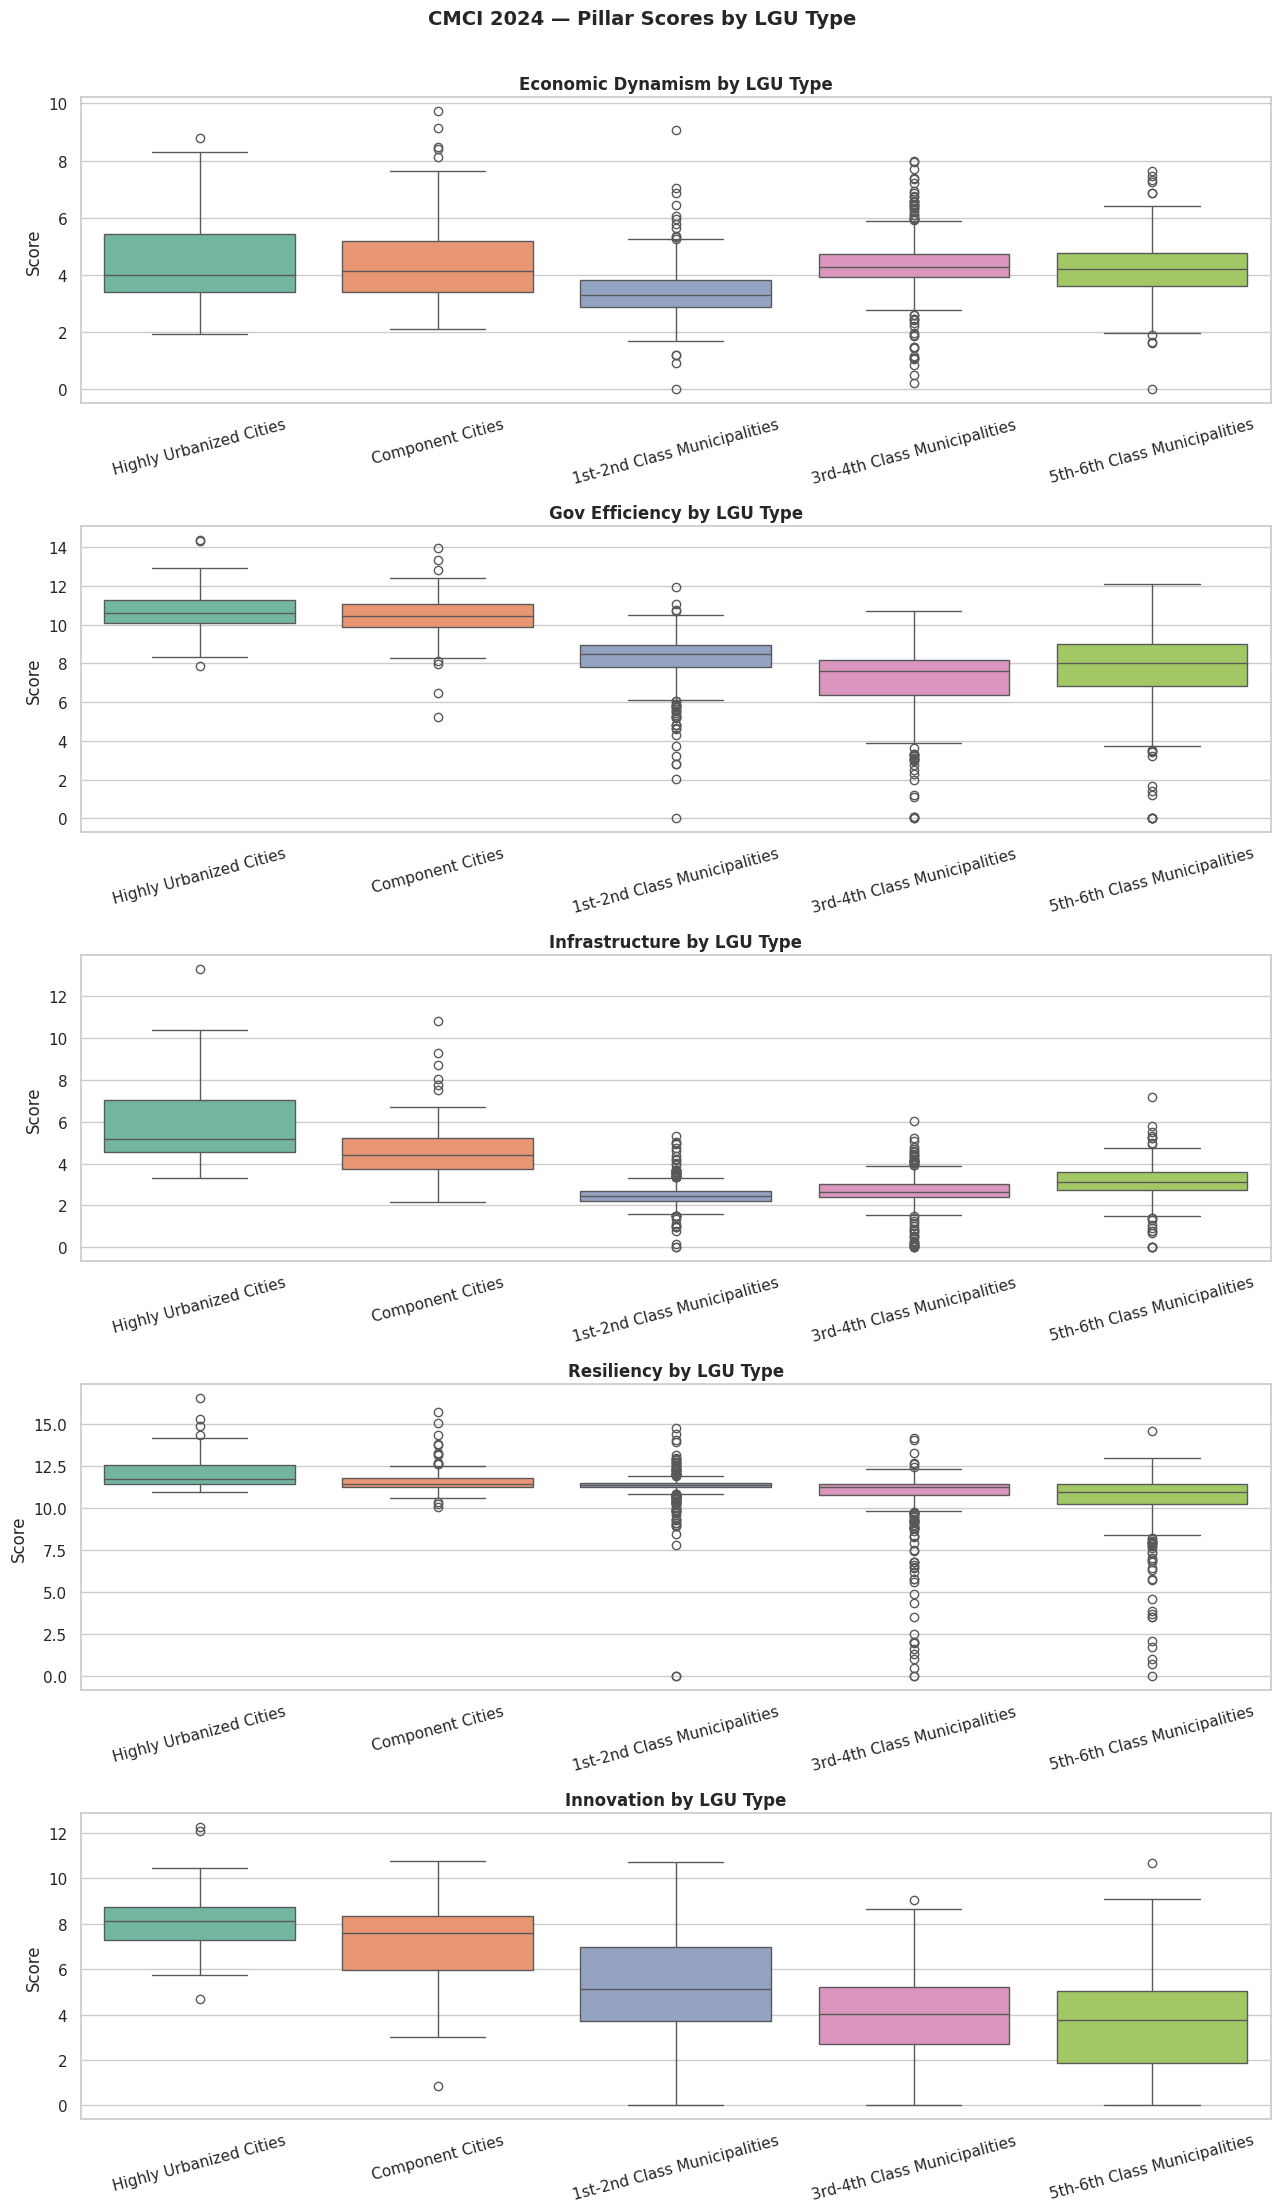

In [6]:
fig, axes = plt.subplots(len(PILLAR_COLS), 1, figsize=(13, 22))
for i, col in enumerate(PILLAR_COLS):
    sns.boxplot(data=df, x='lgu_type', y=col, order=LGU_TYPES, palette='Set2',
                hue='lgu_type', legend=False, ax=axes[i])
    axes[i].set_title(f'{col.replace("_", " ").title()} by LGU Type', fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Score')
    axes[i].tick_params(axis='x', rotation=15)
plt.suptitle('CMCI 2024 — Pillar Scores by LGU Type', fontsize=14, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

### Correlation between pillars

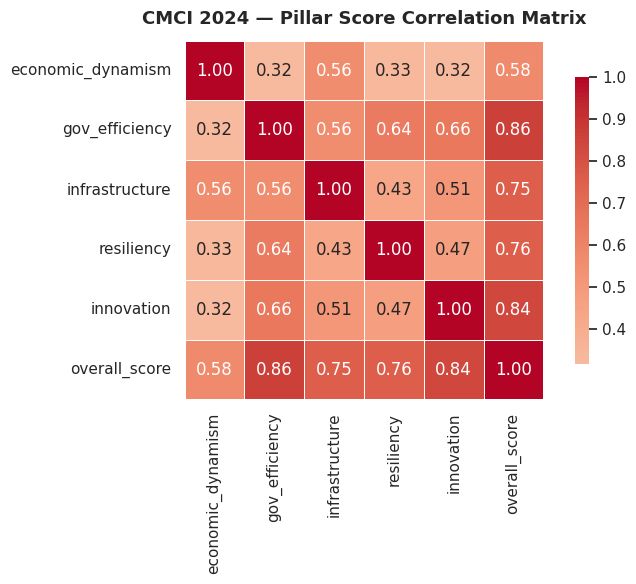

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[PILLAR_COLS + ['overall_score']].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.5, linecolor='white',
            square=True, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('CMCI 2024 — Pillar Score Correlation Matrix', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

## 3. Clustering LGUs into competitiveness tiers

### 3.1 Choosing K
The five pillar scores are standardized, then K-Means is run for K = 2…10.

In [8]:
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(df[PILLAR_COLS])

inertia_vals, silhouette_vals = [], []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia_vals.append(km.inertia_)
    silhouette_vals.append(silhouette_score(X_scaled, km.labels_))
    print(f"K={k:>2}  |  Inertia: {km.inertia_:8.2f}  |  Silhouette: {silhouette_vals[-1]:.4f}")

OPTIMAL_K = list(K_range)[int(np.argmax(silhouette_vals))]
print(f"\nBest K by silhouette: {OPTIMAL_K}  (score = {max(silhouette_vals):.4f})")

K= 2  |  Inertia:  5847.87  |  Silhouette: 0.2618
K= 3  |  Inertia:  4583.89  |  Silhouette: 0.3043


K= 4  |  Inertia:  3728.23  |  Silhouette: 0.2503
K= 5  |  Inertia:  3244.27  |  Silhouette: 0.2288


K= 6  |  Inertia:  2903.01  |  Silhouette: 0.2165
K= 7  |  Inertia:  2668.13  |  Silhouette: 0.2100


K= 8  |  Inertia:  2453.84  |  Silhouette: 0.2207
K= 9  |  Inertia:  2288.85  |  Silhouette: 0.2210


K=10  |  Inertia:  2156.56  |  Silhouette: 0.2153

Best K by silhouette: 3  (score = 0.3043)


Inertia drops sharply from K=2 to K=3 and then flattens (the elbow). The silhouette score also peaks at **K=3** (0.304). Both methods agree on three tiers.

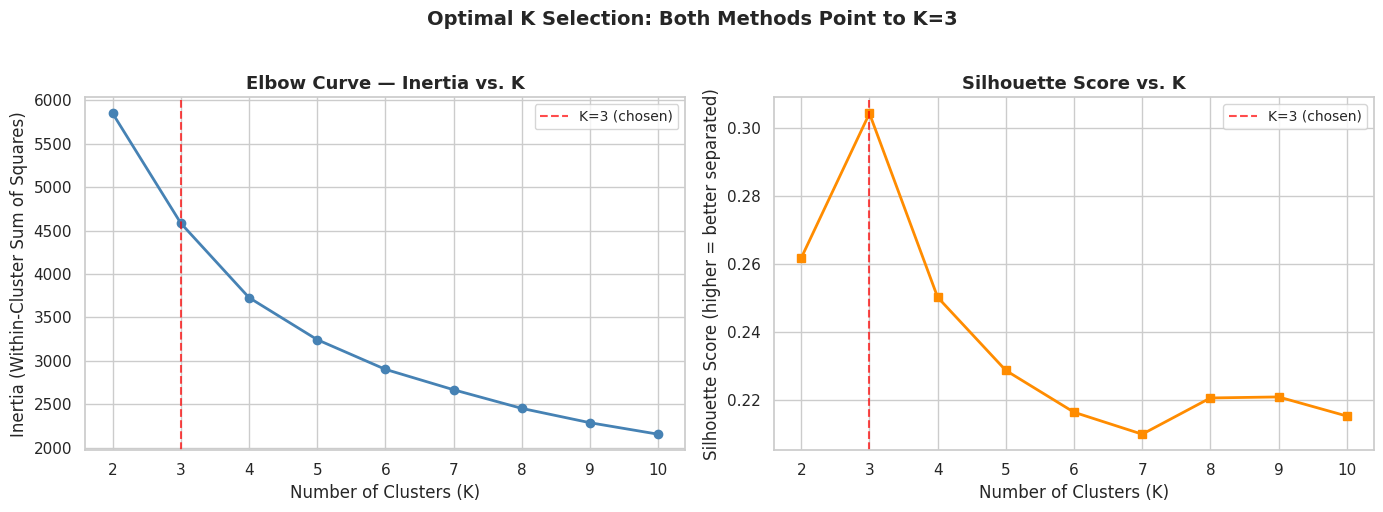

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(K_range), inertia_vals, marker='o', color='steelblue', linewidth=2)
axes[0].axvline(x=OPTIMAL_K, color='red', linestyle='--', alpha=0.7, label=f'K={OPTIMAL_K} (chosen)')
axes[0].set_title('Elbow Curve — Inertia vs. K', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].set_xticks(list(K_range))
axes[0].legend(fontsize=10)

axes[1].plot(list(K_range), silhouette_vals, marker='s', color='darkorange', linewidth=2)
axes[1].axvline(x=OPTIMAL_K, color='red', linestyle='--', alpha=0.7, label=f'K={OPTIMAL_K} (chosen)')
axes[1].set_title('Silhouette Score vs. K', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score (higher = better separated)')
axes[1].set_xticks(list(K_range))
axes[1].legend(fontsize=10)

plt.suptitle(f'Optimal K Selection: Both Methods Point to K={OPTIMAL_K}',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
save_fig('chart_04')
plt.show()

### 3.2 Final model

In [10]:
km_final = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10).fit(X_scaled)
df['cluster'] = km_final.labels_

sizes = df['cluster'].value_counts().sort_index()
for c, n in sizes.items():
    print(f"Cluster {c} ({CLUSTER_NAMES[c]}): {n:,} LGUs ({n / len(df) * 100:.1f}%)")

Cluster 0 (Competitive Leaders): 530 LGUs (32.4%)
Cluster 1 (Critically Underserved): 45 LGUs (2.8%)
Cluster 2 (Developing Mainstream): 1,059 LGUs (64.8%)


### 3.3 Visualizing the clusters (PCA)
The **Critically Underserved** tier (red) is tightly packed and clearly separated. The Leaders (blue) spread across the upper range, and the Mainstream (green) makes up the bulk of LGUs.

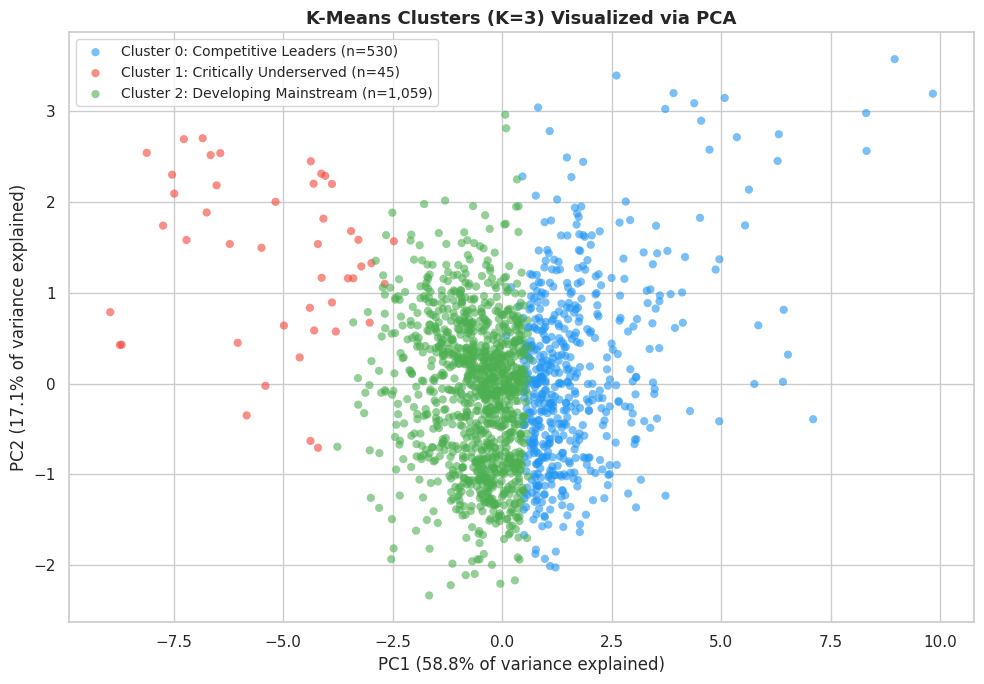

PC1 + PC2 together explain 75.9% of total variance.


In [11]:
pca   = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(10, 7))
for cid in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cid
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], color=CLUSTER_COLORS[cid],
               label=f'Cluster {cid}: {CLUSTER_NAMES[cid]} (n={sizes[cid]:,})',
               alpha=0.6, s=35, edgecolors='none')
ax.set_title(f'K-Means Clusters (K={OPTIMAL_K}) Visualized via PCA', fontsize=13, fontweight='bold')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% of variance explained)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% of variance explained)')
ax.legend(fontsize=10, loc='upper left')
plt.tight_layout()
save_fig('chart_05')
plt.show()

print(f"PC1 + PC2 together explain {pca.explained_variance_ratio_.sum() * 100:.1f}% of total variance.")

### 3.4 Cluster profiles
- **Leaders** score highest on every pillar.
- **Underserved** LGUs are near zero on Infrastructure, Innovation, and Government Efficiency.
- **Mainstream** LGUs are middling, with relative strength in Resiliency.
- Government Efficiency shows the largest absolute gap between Leaders and Underserved (about 14 vs. 2).

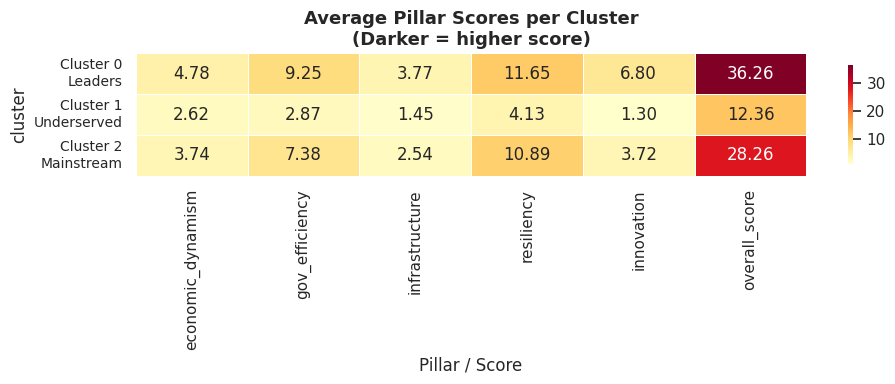

         economic_dynamism  gov_efficiency  infrastructure  resiliency  innovation  overall_score
cluster                                                                                          
0                    4.780           9.249           3.774      11.655       6.805         36.263
1                    2.618           2.865           1.451       4.127       1.302         12.362
2                    3.736           7.383           2.536      10.891       3.716         28.261


In [12]:
cluster_profile = df.groupby('cluster')[PILLAR_COLS + ['overall_score']].mean().round(3)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(cluster_profile, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, linecolor='white', ax=ax, cbar_kws={'shrink': 0.8})
ax.set_yticklabels([f'Cluster {c}\n{CLUSTER_SHORT[c]}' for c in cluster_profile.index],
                   rotation=0, fontsize=10)
ax.set_title('Average Pillar Scores per Cluster\n(Darker = higher score)', fontsize=13, fontweight='bold')
ax.set_xlabel('Pillar / Score')
plt.tight_layout()
save_fig('chart_06')
plt.show()

print(cluster_profile.to_string())

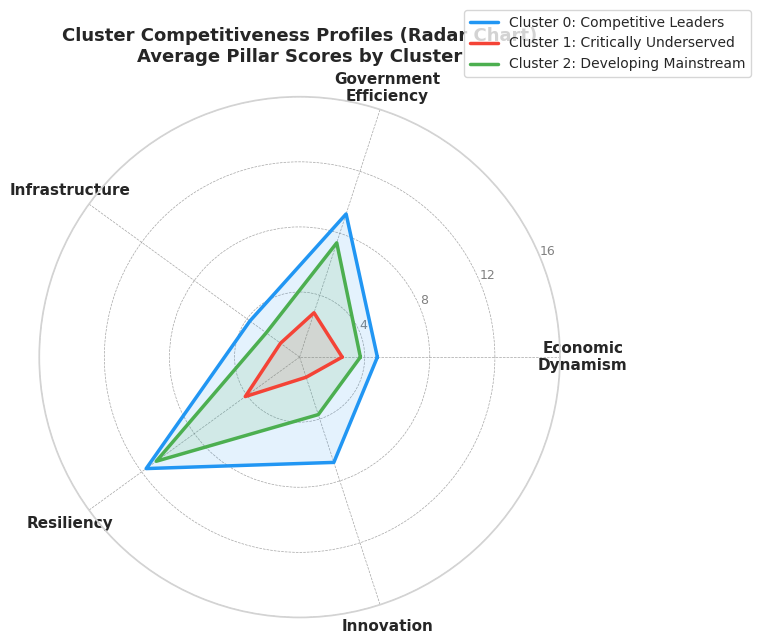

In [13]:
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
profiles = df.groupby('cluster')[PILLAR_COLS].mean()
angles = np.linspace(0, 2 * np.pi, len(PILLAR_COLS), endpoint=False).tolist()
angles += angles[:1]

for cid in sorted(profiles.index):
    vals = profiles.loc[cid, PILLAR_COLS].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, color=CLUSTER_COLORS[cid], linewidth=2.5,
            label=f'Cluster {cid}: {CLUSTER_NAMES[cid]}')
    ax.fill(angles, vals, color=CLUSTER_COLORS[cid], alpha=0.12)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(PILLAR_LABELS, size=11, fontweight='bold')
ax.set_ylim(0, 16)
ax.set_yticks([4, 8, 12, 16])
ax.set_yticklabels(['4', '8', '12', '16'], size=9, color='gray')
ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
ax.spines['polar'].set_color('lightgray')
ax.set_title('Cluster Competitiveness Profiles (Radar Chart)\nAverage Pillar Scores by Cluster',
             fontsize=13, fontweight='bold', pad=25)
ax.legend(loc='upper right', bbox_to_anchor=(1.38, 1.18), fontsize=10)
plt.tight_layout()
save_fig('chart_08')
plt.show()

The three score distributions barely overlap. Leaders average about 42, Mainstream about 30, and Underserved about 13, with a ceiling around 22.

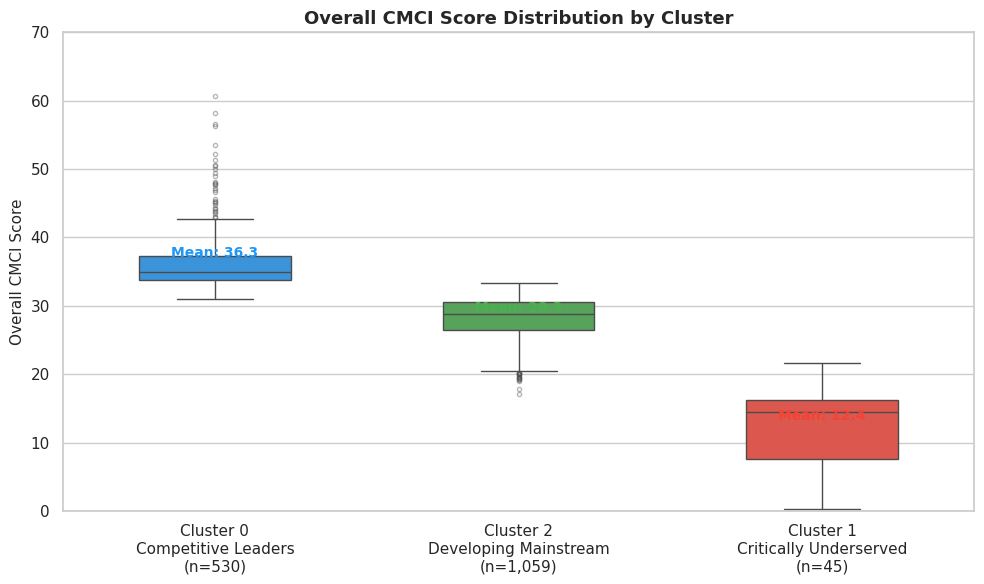

In [14]:
order  = [0, 2, 1]
labels = {c: f'Cluster {c}\n{CLUSTER_NAMES[c]}\n(n={sizes[c]:,})' for c in order}

df_plot = df.assign(Label=df['cluster'].map(labels))
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df_plot, x='Label', y='overall_score', order=[labels[c] for c in order],
            palette=[CLUSTER_COLORS[c] for c in order], hue='Label', legend=False,
            width=0.5, flierprops=dict(marker='o', markersize=3, alpha=0.4), ax=ax)

means = df.groupby('cluster')['overall_score'].mean()
for i, cid in enumerate(order):
    ax.text(i, means[cid] + 0.9, f'Mean: {means[cid]:.1f}',
            ha='center', fontsize=10, fontweight='bold', color=CLUSTER_COLORS[cid])

ax.set_title('Overall CMCI Score Distribution by Cluster', fontsize=13, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Overall CMCI Score', fontsize=11)
ax.set_ylim(0, 70)
plt.tight_layout()
save_fig('chart_09')
plt.show()

### 3.5 Who is in each cluster?
Cluster membership is strongly tied to administrative and income class. All 33 Highly Urbanized Cities and 106 of 116 Component Cities are Leaders. The 45 Underserved LGUs are all municipalities: 25 are 3rd–4th class and 18 are 5th–6th class.

In [15]:
print("Top 5 LGUs per cluster by overall score\n")
for cid in sorted(df['cluster'].unique()):
    top5 = df[df['cluster'] == cid].nlargest(5, 'overall_score')
    print(f"── Cluster {cid}: {CLUSTER_NAMES[cid]} ──")
    print(top5[['LGU', 'Province', 'Region', 'lgu_type', 'overall_score']].to_string(index=False), "\n")

print(pd.crosstab(df['cluster'], df['lgu_type'], margins=True, margins_name='TOTAL').to_string())

Top 5 LGUs per cluster by overall score

── Cluster 0: Competitive Leaders ──
        LGU      Province                        Region                lgu_type  overall_score
Quezon (MM)  Metro Manila NCR - National Capital Region Highly Urbanized Cities        60.6893
  Naga (CS) Camarines Sur       REGION V (Bicol Region)        Component Cities        58.2084
     Manila  Metro Manila NCR - National Capital Region Highly Urbanized Cities        56.6604
      Pasay  Metro Manila NCR - National Capital Region Highly Urbanized Cities        56.3456
 Muntinlupa  Metro Manila NCR - National Capital Region Highly Urbanized Cities        53.5331 

── Cluster 1: Critically Underserved ──
              LGU              Province                                                  Region                     lgu_type  overall_score
            Maigo       Lanao Del Norte                            REGION X (Northern Mindanao) 3rd-4th Class Municipalities        21.6452
    San Sebastian Samar (Weste

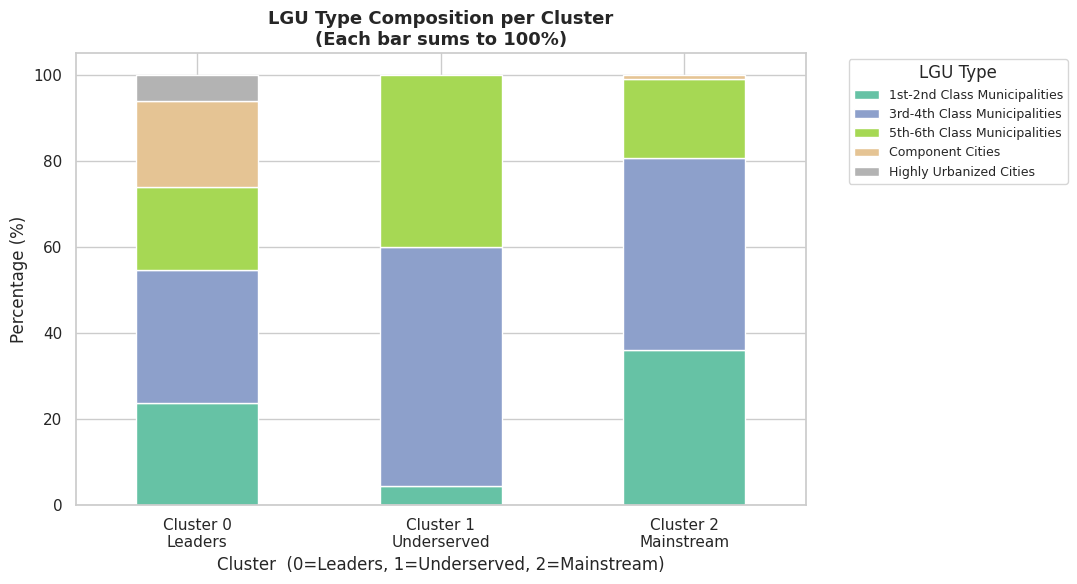

In [16]:
lgu_cluster_pct = pd.crosstab(df['cluster'], df['lgu_type'], normalize='index') * 100

ax = lgu_cluster_pct.plot(kind='bar', stacked=True, figsize=(11, 6),
                          colormap='Set2', edgecolor='white')
plt.title('LGU Type Composition per Cluster\n(Each bar sums to 100%)', fontsize=13, fontweight='bold')
plt.xlabel('Cluster  (0=Leaders, 1=Underserved, 2=Mainstream)')
plt.ylabel('Percentage (%)')
plt.xticks(ticks=range(len(lgu_cluster_pct)),
           labels=[f'Cluster {c}\n{CLUSTER_SHORT[c]}' for c in lgu_cluster_pct.index], rotation=0)
plt.legend(title='LGU Type', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.tight_layout()
save_fig('chart_07')
plt.show()

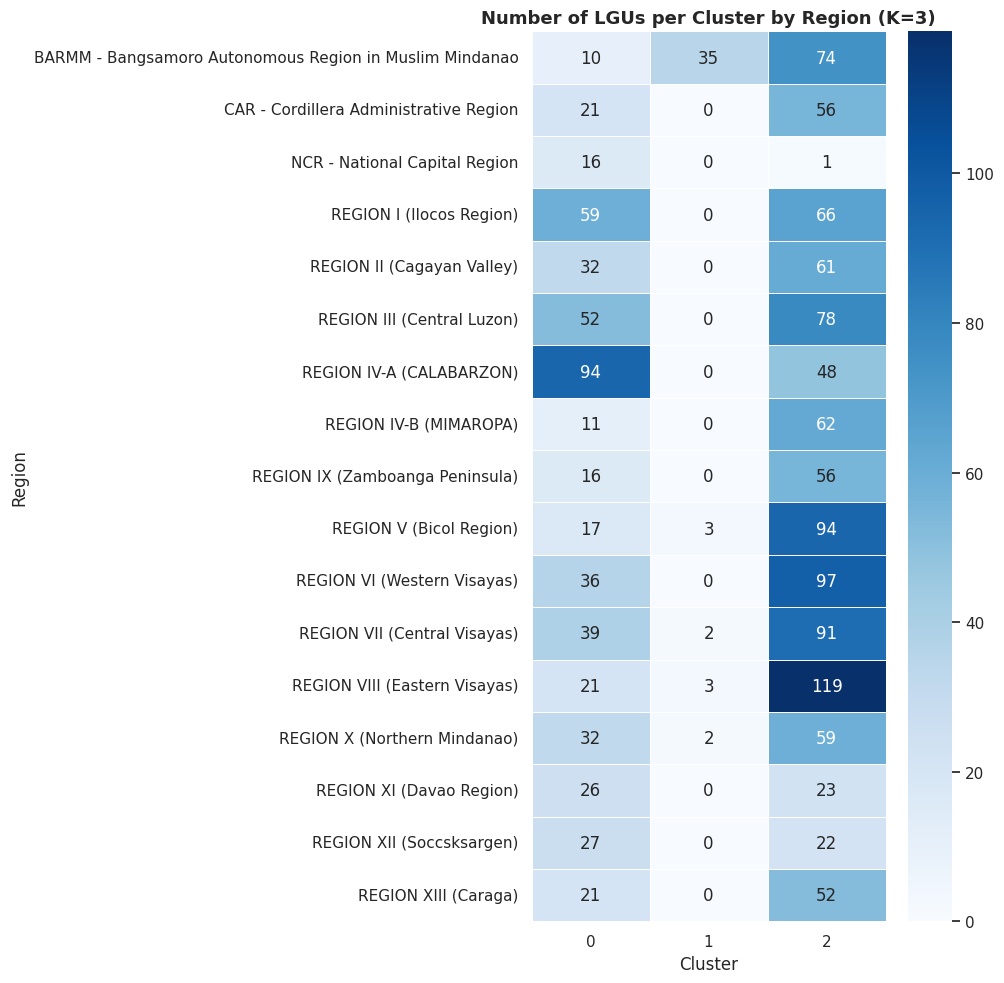

Saved: data/cmci_2024_clustered.csv


In [17]:
region_cluster = pd.crosstab(df['Region'], df['cluster'])

fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(region_cluster, annot=True, fmt='d', cmap='Blues',
            linewidths=0.5, linecolor='white', ax=ax)
ax.set_title(f'Number of LGUs per Cluster by Region (K={OPTIMAL_K})', fontsize=13, fontweight='bold')
ax.set_xlabel('Cluster')
ax.set_ylabel('Region')
plt.tight_layout()
plt.show()

df.to_csv('data/cmci_2024_clustered.csv', index=False)
print("Saved: data/cmci_2024_clustered.csv")

## 4. Top performers and sub-indicators

### 4.1 Top 10 LGUs
Quezon City leads with 60.69 out of 100. All top 10 are Competitive Leaders, and Metro Manila dominates the top 5. Even the best score is only about 60% of the maximum.

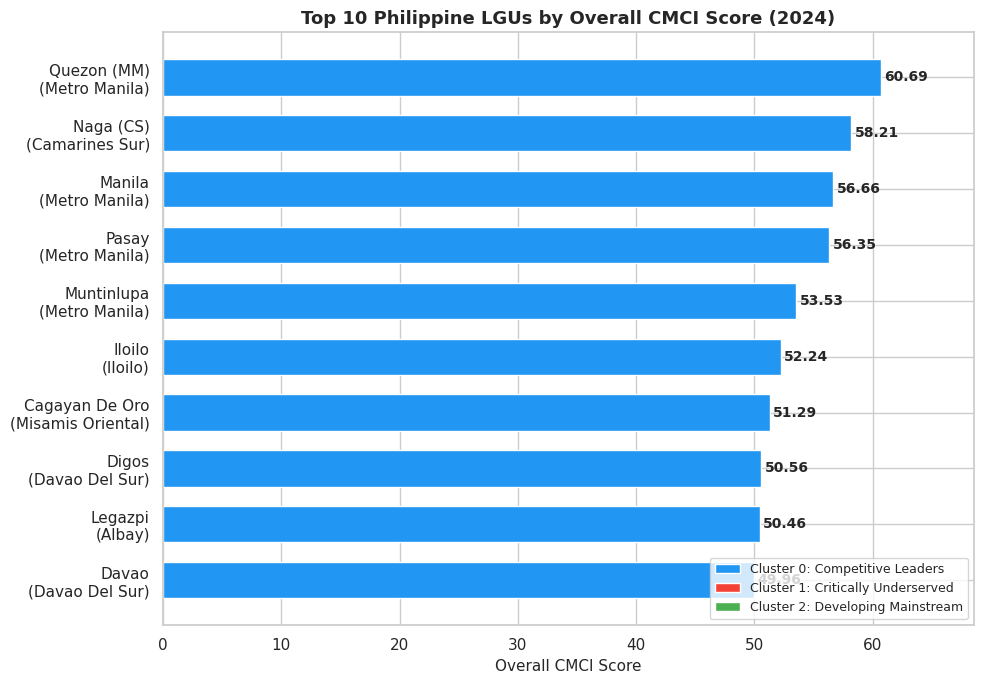

           LGU         Province                lgu_type  overall_score
   Quezon (MM)     Metro Manila Highly Urbanized Cities        60.6893
     Naga (CS)    Camarines Sur        Component Cities        58.2084
        Manila     Metro Manila Highly Urbanized Cities        56.6604
         Pasay     Metro Manila Highly Urbanized Cities        56.3456
    Muntinlupa     Metro Manila Highly Urbanized Cities        53.5331
        Iloilo           Iloilo Highly Urbanized Cities        52.2415
Cagayan De Oro Misamis Oriental Highly Urbanized Cities        51.2943
         Digos    Davao Del Sur        Component Cities        50.5589
       Legazpi            Albay        Component Cities        50.4584
         Davao    Davao Del Sur Highly Urbanized Cities        49.9593


In [18]:
top10_lgu = (df.nlargest(10, 'overall_score')
             [['LGU', 'Province', 'lgu_type', 'cluster', 'overall_score']]
             .reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh([f"{r['LGU']}\n({r['Province']})" for _, r in top10_lgu.iterrows()],
               top10_lgu['overall_score'],
               color=[CLUSTER_COLORS[c] for c in top10_lgu['cluster']],
               edgecolor='white', height=0.65)
for bar, val in zip(bars, top10_lgu['overall_score']):
    ax.text(val + 0.3, bar.get_y() + bar.get_height() / 2,
            f'{val:.2f}', va='center', fontsize=10, fontweight='bold')

ax.invert_yaxis()
ax.set_xlabel('Overall CMCI Score', fontsize=11)
ax.set_xlim(0, top10_lgu['overall_score'].max() * 1.13)
ax.set_title('Top 10 Philippine LGUs by Overall CMCI Score (2024)', fontsize=13, fontweight='bold')
ax.legend(handles=[Patch(facecolor=CLUSTER_COLORS[c], label=f'Cluster {c}: {CLUSTER_NAMES[c]}')
                   for c in CLUSTER_NAMES], fontsize=9, loc='lower right')
plt.tight_layout()
save_fig('chart_01')
plt.show()

print(top10_lgu[['LGU', 'Province', 'lgu_type', 'overall_score']].to_string(index=False))

### 4.2 Load the 50 sub-indicators
Each sub-indicator comes from its own CSV in `data/pillars_data/`. Dashes (`-`) mark values an LGU did not report. They are treated as 0.

In [19]:
INDICATOR_FILES = {
    # Economic Dynamism
    'Local_Economy_Size.csv':                                   'ed_local_economy_size',
    'Local_Economy_Growth.csv':                                 'ed_local_economy_growth',
    'Active_Establishments_in_the_Locality.csv':                'ed_active_establishments',
    'Safety_Compliant_Business.csv':                            'ed_safety_compliant_business',
    'Employment_Generation.csv':                                'ed_employment_generation',
    'Cost_of_Living.csv':                                       'ed_cost_of_living',
    'Cost_of_Doing_Business.csv':                               'ed_cost_of_doing_business',
    'Financial_Deepening.csv':                                  'ed_financial_deepening',
    'Productivity.csv':                                         'ed_productivity',
    'Presence_of_Business_and_Professional_Organizations.csv':  'ed_business_orgs',
    # Government Efficiency
    'Compliance_to_National_Directives.csv':                    'ge_compliance_national',
    'Presence_of_Investment_Promotion_Unit.csv':                'ge_investment_promotion',
    'Compliance_to_ARTA_Citizens_Charter.csv':                  'ge_arta_compliance',
    'Capacity_to_Generate_Local_Resource.csv':                  'ge_local_resource',
    'Capacity_of_Health_Services.csv':                          'ge_health_services',
    'Capacity_of_School_Services.csv':                          'ge_school_services',
    'Recognition_of_Performance.csv':                           'ge_recognition',
    'Getting_Business_Permits.csv':                             'ge_business_permits',
    'Peace_and_Order.csv':                                      'ge_peace_order',
    'Social_Protection.csv':                                    'ge_social_protection',
    # Infrastructure
    'Road_Network.csv':                                         'infra_road_network',
    'Distance_to_Ports.csv':                                    'infra_distance_ports',
    'Availability_of_Basic_Utilities.csv':                      'infra_basic_utilities',
    'Transportation_Vehicles.csv':                              'infra_transportation',
    'Education.csv':                                            'infra_education',
    'Health.csv':                                               'infra_health',
    'LGU_Investment.csv':                                       'infra_lgu_investment',
    'Accommodation_Capacity.csv':                               'infra_accommodation',
    'Information_Technology_Capacity.csv':                      'infra_ict_capacity',
    'Financial_Technology_Capacity.csv':                        'infra_fintech_capacity',
    # Resiliency
    'Land_Use_Plan.csv':                                        'res_land_use_plan',
    'Disaster_Risk_Reduction_Plan.csv':                         'res_drrp',
    'Annual_Disaster_Drill.csv':                                'res_disaster_drill',
    'Early_Warning_System.csv':                                 'res_early_warning',
    'Budget_for_DRRMP.csv':                                     'res_drrmp_budget',
    'Local_Risk_Assessments.csv':                               'res_risk_assessments',
    'Emergency_Infrastructure.csv':                             'res_emergency_infra',
    'Utilities.csv':                                            'res_utilities',
    'Employed_Population.csv':                                  'res_employed_population',
    'Sanitary_System.csv':                                      'res_sanitary_system',
    # Innovation
    'ICT_Plan.csv':                                             'inn_ict_plan',
    'Innovation_Financing_RD_Expenditures_Allotment.csv':       'inn_rd_expenditure',
    'ICT_Use_E-BPLS_Software.csv':                              'inn_ebpls',
    'Online_Payment_Facilities.csv':                            'inn_online_payment',
    'STEM_graduates.csv':                                       'inn_stem_graduates',
    'Intellectual_Property_Registration.csv':                   'inn_ip_registration',
    'Internet_Capability.csv':                                  'inn_internet_capability',
    'Availability_of_Basic_Internet_Service.csv':               'inn_basic_internet',
    'Start_Up_and_Innovation_Facilities.csv':                   'inn_startup_facilities',
    'New_Technology.csv':                                       'inn_new_technology',
}
INDICATOR_COLS = list(INDICATOR_FILES.values())
PILLARS_DIR = 'data/pillars_data'

frames = []
for filename, col_name in INDICATOR_FILES.items():
    tmp = pd.read_csv(os.path.join(PILLARS_DIR, filename))
    tmp = tmp.rename(columns={'Province / LGU': 'LGU_key', '2024': col_name})
    tmp['LGU_key'] = tmp['LGU_key'].str.strip().str.lower()
    tmp[col_name] = pd.to_numeric(tmp[col_name].astype(str).str.strip(), errors='coerce')  # '-' → NaN
    frames.append(tmp)

df_indicators = reduce(lambda l, r: pd.merge(l, r, on='LGU_key', how='inner'), frames)

n_missing = df_indicators[INDICATOR_COLS].isnull().sum()
print(f"Sub-indicator table: {df_indicators.shape}")
print(f"Unreported values ('-') filled with 0: {int(n_missing.sum())}")
print(n_missing[n_missing > 0].to_string())

df_indicators[INDICATOR_COLS] = df_indicators[INDICATOR_COLS].fillna(0)
df_indicators.to_csv('data/cmci_2024_indicators.csv', index=False)

Sub-indicator table: (1634, 51)
Unreported values ('-') filled with 0: 1
ed_active_establishments    1


In [20]:
# Join sub-indicators onto the clustered LGU table (case-insensitive name match)
df_master = (df.assign(LGU_key=df['LGU'].str.strip().str.lower())
               .merge(df_indicators, on='LGU_key', how='left')
               .drop(columns='LGU_key'))

unmatched = df_master[INDICATOR_COLS[0]].isnull().sum()
print(f"df_master: {df_master.shape}  |  LGUs without sub-indicator data: {unmatched}")
df_master.to_csv('data/cmci_2024_master.csv', index=False)

df_master: (1634, 67)  |  LGUs without sub-indicator data: 0


### 4.3 What do the top 10 LGUs excel at?
Top LGUs score consistently high on **Resiliency** (disaster-risk and land-use plans, emergency infrastructure) and **Government Efficiency** (health and school capacity). Their strength is broad rather than concentrated in one area.

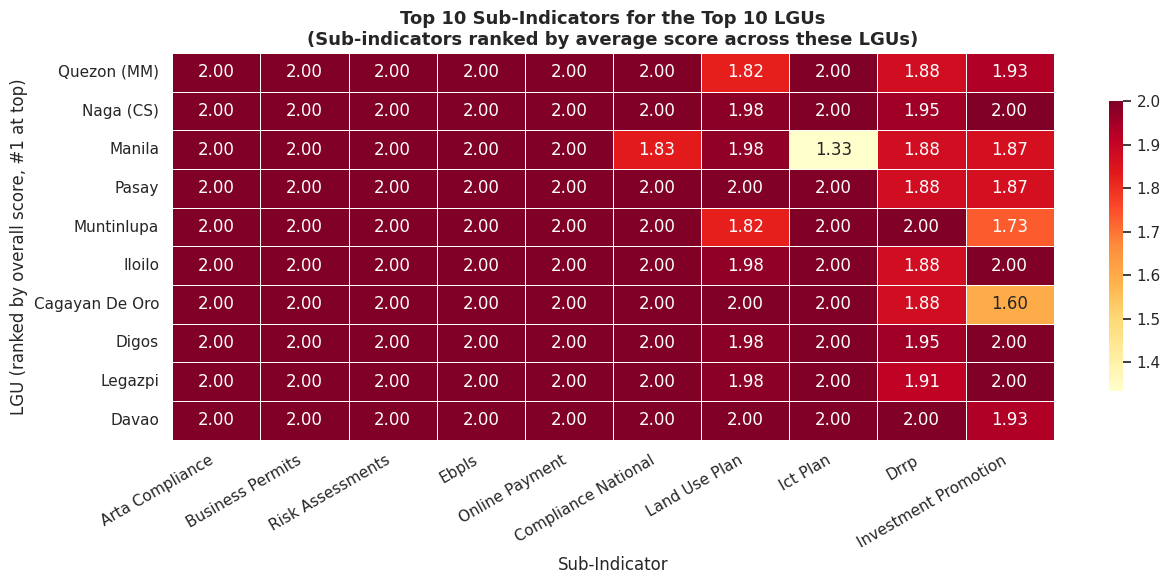

In [21]:
top10_names = top10_lgu['LGU'].tolist()
top10_data  = df_master.set_index('LGU').loc[top10_names, INDICATOR_COLS]
top10_ind   = top10_data.mean().nlargest(10).index.tolist()

heatmap_df = top10_data[top10_ind].copy()
heatmap_df.columns = [clean_label(c) for c in heatmap_df.columns]

fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(heatmap_df, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, linecolor='white', ax=ax, cbar_kws={'shrink': 0.75})
ax.set_title('Top 10 Sub-Indicators for the Top 10 LGUs\n'
             '(Sub-indicators ranked by average score across these LGUs)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Sub-Indicator')
ax.set_ylabel('LGU (ranked by overall score, #1 at top)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
save_fig('chart_02')
plt.show()

## 5. Which sub-indicators drive each tier?

An **L1-penalized multinomial logistic regression** predicts cluster membership from the 50 raw sub-indicators, *without* the pillar scores used to build the clusters. The L1 penalty drops uninformative indicators to exactly zero, which leaves a sparse, interpretable set of drivers. `class_weight='balanced'` compensates for the small Underserved class (45 LGUs).

In [22]:
X = df_master[INDICATOR_COLS].values   # (1634, 50)
y = df_master['cluster'].values        # (1634,)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler_clf     = StandardScaler()
X_train_scaled = scaler_clf.fit_transform(X_train)
X_test_scaled  = scaler_clf.transform(X_test)

clf = LogisticRegressionCV(Cs=20, cv=5, penalty='l1', solver='saga',
                           class_weight='balanced', max_iter=5000,
                           random_state=42, n_jobs=-1)
clf.fit(X_train_scaled, y_train)

coef_matrix = pd.DataFrame(clf.coef_, index=[f'Cluster {c}' for c in clf.classes_],
                           columns=INDICATOR_COLS)

print(f"Train: {len(y_train)} LGUs  |  Test: {len(y_test)} LGUs\n")
for row in coef_matrix.index:
    print(f"{row}: {(coef_matrix.loc[row].abs() > 1e-6).sum()} of 50 sub-indicators active")

Train: 1307 LGUs  |  Test: 327 LGUs

Cluster 0: 45 of 50 sub-indicators active
Cluster 1: 19 of 50 sub-indicators active
Cluster 2: 16 of 50 sub-indicators active


### 5.1 Model performance
Leaders and Mainstream are classified almost perfectly. Underserved is the hardest class because there are only 9 test LGUs, but every one of them is recovered (recall = 1.00).

Test accuracy: 97.9%

                        precision    recall  f1-score   support

   Competitive Leaders       0.97      0.97      0.97       106
Critically Underserved       0.90      1.00      0.95         9
 Developing Mainstream       0.99      0.98      0.98       212

              accuracy                           0.98       327
             macro avg       0.95      0.98      0.97       327
          weighted avg       0.98      0.98      0.98       327



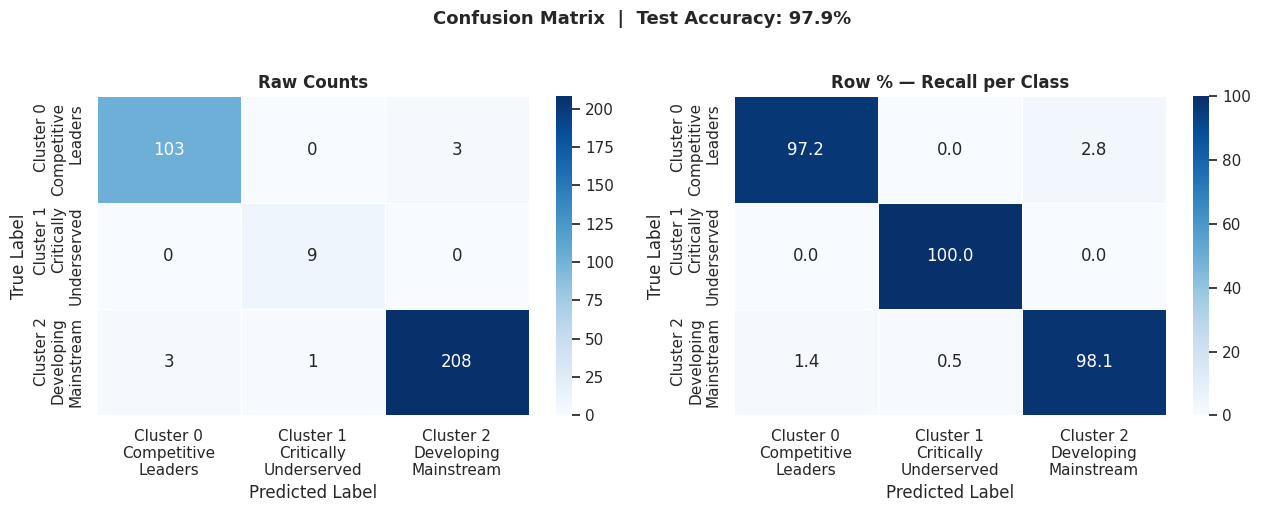

In [23]:
y_pred = clf.predict(X_test_scaled)
acc    = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {acc*100:.1f}%\n")
print(classification_report(y_test, y_pred, target_names=[CLUSTER_NAMES[c] for c in clf.classes_]))

cm     = confusion_matrix(y_test, y_pred)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
tick_labels = [f"Cluster {c}\n{CLUSTER_NAMES[c].replace(' ', chr(10))}" for c in clf.classes_]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, data, fmt, title in [(axes[0], cm, 'd', 'Raw Counts'),
                             (axes[1], cm_pct, '.1f', 'Row % — Recall per Class')]:
    sns.heatmap(data, annot=True, fmt=fmt, cmap='Blues', xticklabels=tick_labels,
                yticklabels=tick_labels, linewidths=0.5, ax=ax)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
plt.suptitle(f'Confusion Matrix  |  Test Accuracy: {acc*100:.1f}%', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
save_fig('chart_10')
plt.show()

### 5.2 Top sub-indicators per cluster
A positive coefficient pushes an LGU *toward* that cluster. A negative one pushes it away.
- **Leaders** are pulled up by digital governance and services: online payment facilities, basic utilities, business-permit processing, e-BPLS, and an ICT plan.
- **Underserved** LGUs are defined by what they *lack*. Every top coefficient is negative: land-use plans, disaster drills, risk assessments, ARTA compliance, active businesses, and health services.
- **Mainstream** LGUs are separated from the Leaders mainly by weaker internet access, start-up facilities, and STEM graduates.

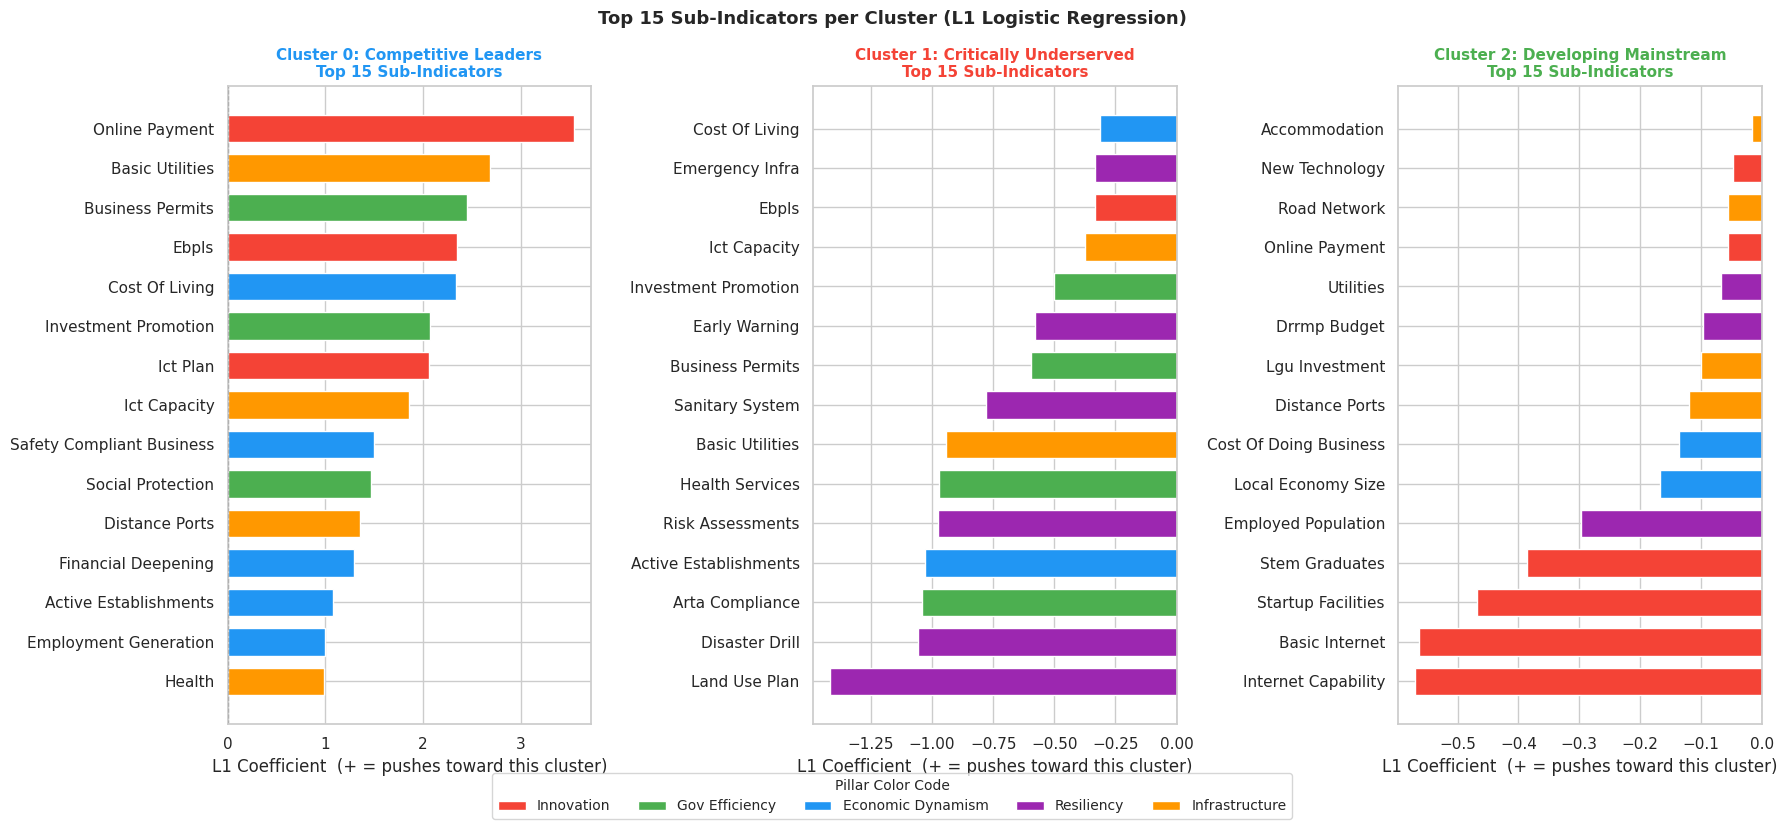

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, cid in zip(axes, clf.classes_):
    coefs = coef_matrix.loc[f'Cluster {cid}']
    top_c = coefs[coefs.abs().nlargest(15).index].sort_values()
    ax.barh([clean_label(n) for n in top_c.index], top_c.values,
            color=[pillar_color(n) for n in top_c.index], edgecolor='white', height=0.7)
    ax.axvline(x=0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(f'Cluster {cid}: {CLUSTER_NAMES[cid]}\nTop 15 Sub-Indicators',
                 fontsize=11, fontweight='bold', color=CLUSTER_COLORS[cid])
    ax.set_xlabel('L1 Coefficient  (+ = pushes toward this cluster)')

fig.legend(handles=PILLAR_LEGEND, loc='lower center', ncol=5, fontsize=10,
           title='Pillar Color Code', title_fontsize=10, bbox_to_anchor=(0.5, -0.04))
plt.suptitle('Top 15 Sub-Indicators per Cluster (L1 Logistic Regression)', fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('chart_11')
plt.show()

### 5.3 Which pillar matters most?
Importance is the sum of absolute coefficients across each pillar's 10 sub-indicators.
- **Leaders:** Innovation (10.54) edges out Government Efficiency (9.94) and Infrastructure (9.76). Reaching the top tier takes strength almost everywhere.
- **Underserved:** Resiliency deficits (5.40) dominate, followed by Government Efficiency (3.54).
- **Mainstream:** Innovation (2.09) is the main differentiator. These LGUs have the basics but lack digital and innovation capacity.

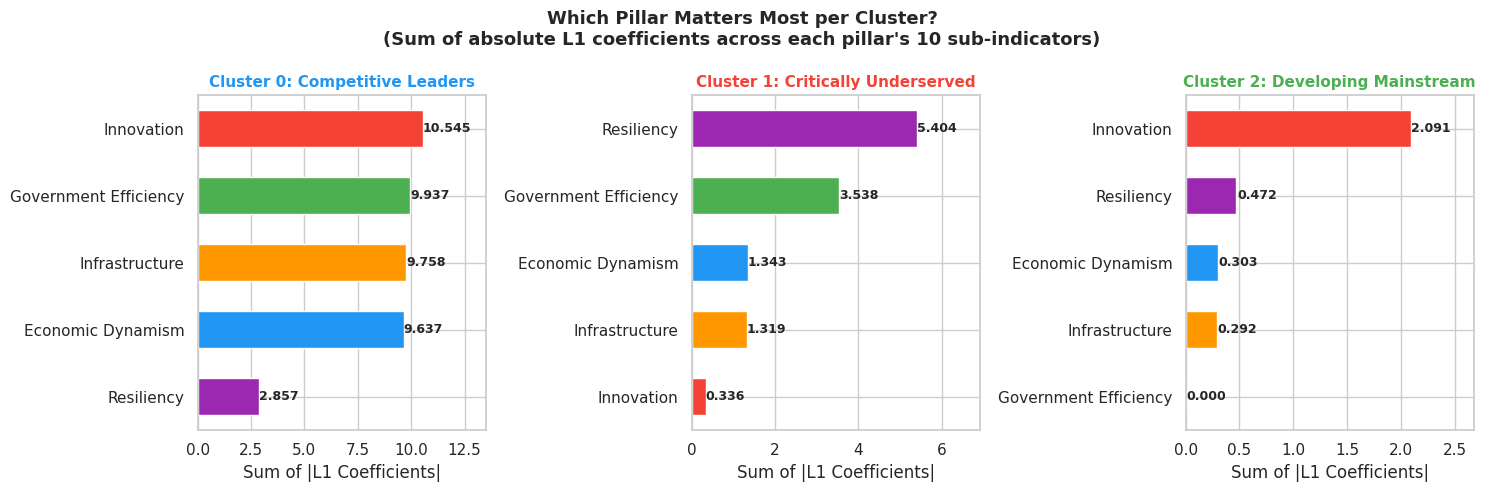

,Cluster 0,Cluster 1,Cluster 2
Economic Dynamism,9.6375,1.3426,0.3033
Government Efficiency,9.9372,3.5385,0.0000
Infrastructure,9.7576,1.3192,0.2916
Resiliency,2.8565,5.4039,0.4722
Innovation,10.5448,0.3356,2.0913


In [25]:
pillar_importance = pd.DataFrame({
    name: coef_matrix[[c for c in INDICATOR_COLS if c.startswith(prefix)]].abs().sum(axis=1)
    for prefix, name in PILLAR_PREFIX_NAMES.items()
}).T
pillar_color_by_name = {name: PILLAR_PREFIX_COLORS[p] for p, name in PILLAR_PREFIX_NAMES.items()}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, cid in zip(axes, clf.classes_):
    imp_s = pillar_importance[f'Cluster {cid}'].sort_values()
    bars  = ax.barh(imp_s.index, imp_s.values, color=[pillar_color_by_name[p] for p in imp_s.index],
                    edgecolor='white', height=0.55)
    for bar, val in zip(bars, imp_s.values):
        ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2,
                f'{val:.3f}', va='center', fontsize=9, fontweight='bold')
    ax.set_title(f'Cluster {cid}: {CLUSTER_NAMES[cid]}', fontsize=11,
                 fontweight='bold', color=CLUSTER_COLORS[cid])
    ax.set_xlabel('Sum of |L1 Coefficients|')
    ax.set_xlim(0, imp_s.max() * 1.28)

plt.suptitle("Which Pillar Matters Most per Cluster?\n"
             "(Sum of absolute L1 coefficients across each pillar's 10 sub-indicators)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('chart_12')
plt.show()

pillar_importance.round(4)

### 5.4 What makes an LGU "Critically Underserved"?
This is the most policy-relevant view. Every top coefficient is negative, so each bar is something whose *absence* pushes an LGU into the Underserved tier. The strongest warning signs are missing **Resiliency** basics (land-use plan, disaster drills, risk assessments, sanitation) and weak **Government Efficiency** (ARTA compliance, health services, business permits). Deprivation is compound, which argues for coordinated, multi-pillar support rather than single-sector programs.

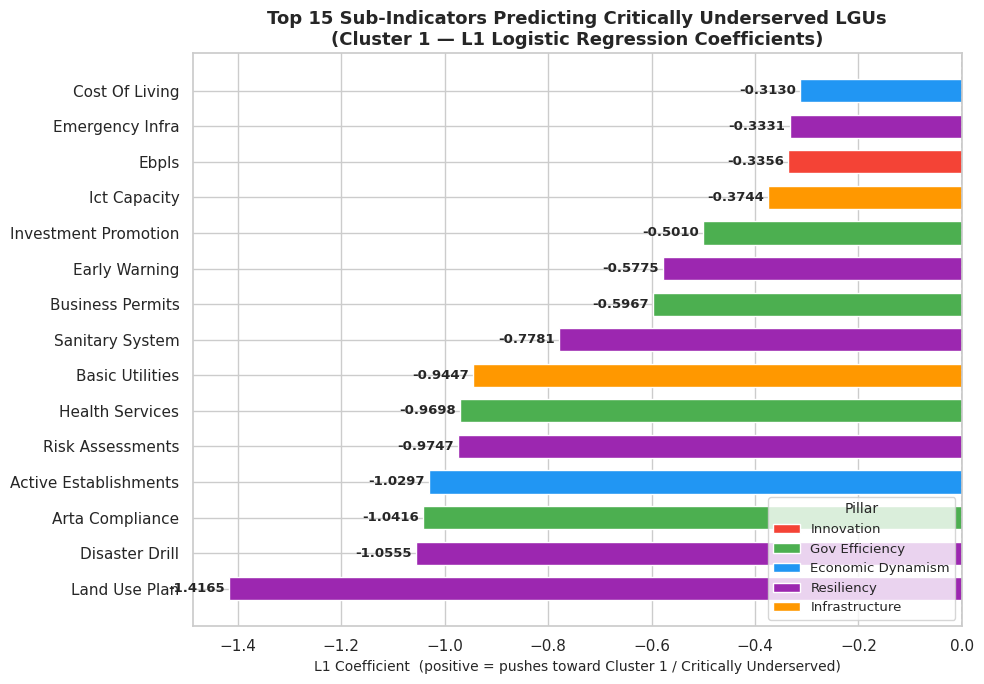

In [26]:
coefs_c1  = coef_matrix.loc['Cluster 1']
top_coefs = coefs_c1[coefs_c1.abs().nlargest(15).index].sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh([clean_label(n) for n in top_coefs.index], top_coefs.values,
               color=[pillar_color(n) for n in top_coefs.index], edgecolor='white', height=0.65)
for bar, val in zip(bars, top_coefs.values):
    ax.text(val + (0.008 if val >= 0 else -0.008), bar.get_y() + bar.get_height() / 2,
            f'{val:+.4f}', va='center', ha='left' if val >= 0 else 'right',
            fontsize=9.5, fontweight='bold')

ax.axvline(x=0, color='black', linewidth=1.0, linestyle='--')
ax.set_title('Top 15 Sub-Indicators Predicting Critically Underserved LGUs\n'
             '(Cluster 1 — L1 Logistic Regression Coefficients)', fontsize=13, fontweight='bold')
ax.set_xlabel('L1 Coefficient  (positive = pushes toward Cluster 1 / Critically Underserved)', fontsize=10)
ax.legend(handles=PILLAR_LEGEND, loc='lower right', fontsize=9.5, title='Pillar', title_fontsize=10)
plt.tight_layout()
save_fig('chart_13')
plt.show()

## 6. At-risk watchlist
Applying the classifier to all 1,634 LGUs gives each one a probability of being Critically Underserved. The LGUs ranked highest form a watchlist that could help prioritize development funds or technical assistance. The probability histograms show that the model separates the tiers with high confidence.

Accuracy on all 1,634 LGUs: 99.3%

Top 15 LGUs by predicted probability of being Critically Underserved
           LGU      Province                     lgu_type  cluster  overall_score  prob_underserved
         Siasi          Sulu 1st-2nd Class Municipalities        1         1.6686               1.0
   Tagoloan II Lanao Del Sur 3rd-4th Class Municipalities        1         6.4717               1.0
 Poona Bayabao Lanao Del Sur 3rd-4th Class Municipalities        1         7.0562               1.0
       Patikul          Sulu 3rd-4th Class Municipalities        1         0.2597               1.0
       Pandami          Sulu 3rd-4th Class Municipalities        1         6.1770               1.0
      Tamparan Lanao Del Sur 5th-6th Class Municipalities        1         2.6752               1.0
        Pualas Lanao Del Sur 5th-6th Class Municipalities        1         7.8278               1.0
       Tubaran Lanao Del Sur 3rd-4th Class Municipalities        1         5.1234               

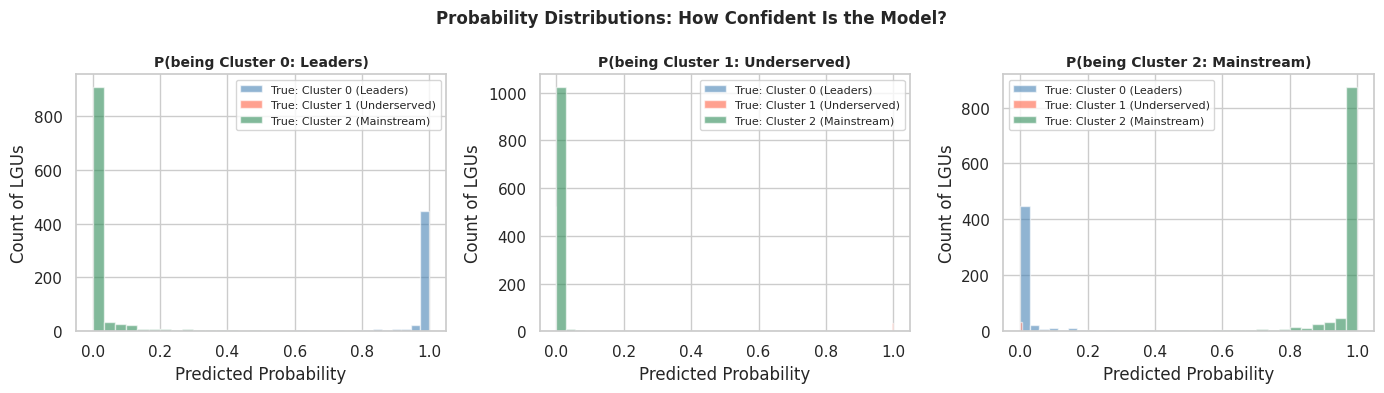


Saved: data/cmci_2024_final.csv


In [27]:
X_all_scaled = scaler_clf.transform(X)
proba        = clf.predict_proba(X_all_scaled)

df_master['pred_cluster']     = clf.predict(X_all_scaled)
df_master['prob_underserved'] = proba[:, list(clf.classes_).index(1)]

df_master['correct'] = df_master['pred_cluster'] == df_master['cluster']
full_acc = df_master['correct'].mean()
print(f"Accuracy on all {len(df_master):,} LGUs: {full_acc*100:.1f}%\n")

print("Top 15 LGUs by predicted probability of being Critically Underserved")
print(df_master.nlargest(15, 'prob_underserved')
      [['LGU', 'Province', 'lgu_type', 'cluster', 'overall_score', 'prob_underserved']]
      .to_string(index=False))

hist_colors = {0: 'steelblue', 1: 'tomato', 2: 'seagreen'}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, clf.classes_):
    prob_col = proba[:, list(clf.classes_).index(c)]
    for true_c in clf.classes_:
        mask = df_master['cluster'] == true_c
        ax.hist(prob_col[mask], bins=25, alpha=0.6, color=hist_colors[true_c], edgecolor='white',
                label=f'True: Cluster {true_c} ({CLUSTER_SHORT[true_c]})')
    ax.set_title(f'P(being Cluster {c}: {CLUSTER_SHORT[c]})', fontsize=10, fontweight='bold')
    ax.set_xlabel('Predicted Probability')
    ax.set_ylabel('Count of LGUs')
    ax.legend(fontsize=8)
plt.suptitle('Probability Distributions: How Confident Is the Model?', fontsize=12, fontweight='bold')
plt.tight_layout()
save_fig('chart_14')
plt.show()

df_master.to_csv('data/cmci_2024_final.csv', index=False)
print("\nSaved: data/cmci_2024_final.csv")

## Key findings

1. **There is a severe, measurable competitiveness divide.** Only 45 of 1,634 LGUs (2.8%) are Critically Underserved, but they score near zero on *every* pillar. The gap between the best (Quezon City, 60.7) and the worst (Lugus, Sulu, 1.0) is extreme.
2. **Three natural tiers exist.** The elbow curve and the silhouette score (0.304) both select K=3, and PCA shows well-separated groups. Tier membership tracks LGU income class closely.
3. **Innovation is the ceiling and Resiliency is the floor.** Innovation carries the most weight for the Leaders tier, and Resiliency deficits (no land-use plan, no disaster drills or risk assessments) most strongly mark the Underserved tier, followed by weak governance.
4. **The model produces an actionable watchlist.** Using only the 50 raw sub-indicators, the L1 classifier reaches **97.9% test accuracy**. It flags municipalities in Sulu, Lanao del Sur, and Basilan as the highest-risk LGUs.

**Policy implications:**
1. Invest in ICT and STEM capacity to help Mainstream LGUs move up.
2. Give the 45 Underserved LGUs coordinated, multi-pillar support.
3. Use the model's probabilities as an ongoing screening tool.

**Limitations:** the analysis uses a single-year snapshot, so it can't support causal claims. The classifier also predicts labels that K-Means created, so its high accuracy shows internal consistency rather than validation against independent ground truth.